# Exercício Prático II
## Aprendizado de máquina A

***Aluna: Lívia Caroline Rodrigues Pereira***

***Matrícula: 2024024003***


> O trabalho foi realizado utilizando o Drive como pasta principal, de forma que o carregamento de dados pode ser alterado para se rodar localmente (o formato estará comentado). Além disso, LLMs (Gemini 3.1 Pro) foram utilizadas para auxiliar na geração, organização e entendimento dos códigos. A parte de esquemas e explicação estão no pdf desse exercício.




In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


Mounted at /content/drive


In [2]:
# Definir o caminho dos dados no Google Drive (ajuste se estiver dentro de outra pasta no seu Drive)
data_dir = '/content/drive/MyDrive/database/2026.2/am/ep2/dados_tp2'

In [3]:
# Carregar arquivos
# Se local. precisaria redefinir data_dir

df1 = pd.read_csv(os.path.join(data_dir, 'secao1.csv'))
df_tuning = pd.read_csv(os.path.join(data_dir, 'dados_tuning.csv'))

## Árvores de Classificação 2D

a) Split Exaustivo

In [4]:
def calcular_gini(y):
    # Retorna 0 se o nó estiver vazio
    if len(y) == 0:
        return 0.0

    # Conta a frequência relativa (p_k) de cada classe
    probabilidades = y.value_counts(normalize=True).values

    # Aplica a fórmula do Gini
    gini = 1.0 - np.sum(probabilidades ** 2)
    return gini

In [5]:
# Variáveis iniciais
melhor_ganho = -1
melhor_split = None
gini_pai = calcular_gini(df1['y']) # Impureza antes da divisão

# Iterar sobre os atributos exigidos
for xj in ['x1', 'x2']:
    # Obter os valores únicos ordenados (substitui o df.orderby)
    valores_ordenados = np.sort(df1[xj].unique())

    # Calcular todos os pontos médios consecutivos vetorizadamente
    pontos_medios = (valores_ordenados[:-1] + valores_ordenados[1:]) / 2

    # Busca exaustiva em todos os limiares t (substitui o while da mediana)
    for t in pontos_medios:
        # Partição dos dados
        df_left = df1[df1[xj] <= t]
        df_right = df1[df1[xj] > t]

        # Ponderação dos nós filhos (|L|/|P| e |R|/|P|)
        peso_left = len(df_left) / len(df1)
        peso_right = len(df_right) / len(df1)

        # Impureza ponderada pós-split
        gini_filhos = (peso_left * calcular_gini(df_left['y'])) + (peso_right * calcular_gini(df_right['y']))

        # Ganho de Informação: Impureza Pai - Impureza Filhos ponderada
        ganho = gini_pai - gini_filhos

        # Atualização do melhor split se encontrarmos um ganho superior
        if ganho > melhor_ganho:
            melhor_ganho = ganho
            melhor_split = {
                'atributo': xj,
                'limiar': t,
                'ganho': ganho,
                'df_left': df_left,
                'df_right': df_right
            }

In [6]:
print(f"Melhor Split Encontrado: Atributo {melhor_split['atributo']} <= {melhor_split['limiar']:.4f}")
print(f"Ganho de Informação: {melhor_split['ganho']:.4f}\n")

# Extrair os conjuntos resultantes do melhor split
df_esq = melhor_split['df_left']
df_dir = melhor_split['df_right']

# Criar uma tabela 2x2 de contagens (utilizando a classe verdadeira 'y')
tabela_contagens = pd.DataFrame({
    'Nó Esquerdo (<= t)': df_esq['y'].value_counts(),
    'Nó Direito (> t)': df_dir['y'].value_counts()
}).fillna(0).astype(int)

tabela_contagens.index.name = 'Classe (y)'
print("Tabela de Contagens por Classe nos Nós Filhos:")
display(tabela_contagens)

Melhor Split Encontrado: Atributo x1 <= 0.6228
Ganho de Informação: 0.1195

Tabela de Contagens por Classe nos Nós Filhos:


,Nó Esquerdo (<= t),Nó Direito (> t)
Classe (y),,
0,248,59
1,59,134


b) Árvore recursiva

In [7]:
def calcular_gini(y):
    """Calcula a impureza de Gini para um conjunto de rótulos."""
    if len(y) == 0:
        return 0.0
    probabilidades = y.value_counts(normalize=True).values
    return 1.0 - np.sum(probabilidades ** 2)

def encontrar_melhor_split(df, n_min=1):
    """
    Busca exaustiva para encontrar o particionamento que maximiza o Ganho de Informação.
    Testa pontos médios para todos os atributos numéricos.
    Só aceita splits em que AMBOS os filhos tenham pelo menos n_min amostras
    (n_min = mínimo de amostras por folha).
    """
    melhor_ganho = -1
    melhor_split = None

    y = df['y']
    gini_pai = calcular_gini(y)

    # Isolar apenas as colunas preditoras (x1, x2, etc.), ignorando os rótulos
    atributos = [col for col in df.columns if col not in ['y', 'y_true']]

    for xj in atributos:
        # 1. Extrair valores únicos e ordená-cols
        valores_ordenados = np.sort(df[xj].unique())

        # Se houver apenas um valor único, é impossível particionar por este atributo
        if len(valores_ordenados) <= 1:
            continue

        # 2. Calcular todos os limiares t (pontos médios)
        pontos_medios = (valores_ordenados[:-1] + valores_ordenados[1:]) / 2

        # 3. Testar cada limiar t
        for t in pontos_medios:
            # Particionamento vetorial dos dados[cite: 11]
            mascara_esq = df[xj] <= t
            df_left = df[mascara_esq]
            df_right = df[~mascara_esq]

            # Mínimo de amostras por folha: descarta splits que gerariam um filho com menos de n_min amostras
            # (com n_min >= 1, isso também elimina nós vazios)
            if len(df_left) < n_min or len(df_right) < n_min:
                continue

            # 4. Cálculo ponderado da impureza pós-split[cite: 11]
            peso_left = len(df_left) / len(df)
            peso_right = len(df_right) / len(df)

            gini_filhos = (peso_left * calcular_gini(df_left['y'])) + \
                          (peso_right * calcular_gini(df_right['y']))

            # 5. Ganho de Informação[cite: 11]
            ganho = gini_pai - gini_filhos

            # 6. Atualização do melhor candidato
            if ganho > melhor_ganho:
                melhor_ganho = ganho
                melhor_split = {
                    'atributo': xj,
                    'limiar': t,
                    'ganho': ganho,
                    'df_left': df_left,
                    'df_right': df_right
                }

    return melhor_split

In [8]:
class NoArvore:
    def __init__(self, atributo=None, limiar=None, esquerdo=None, direito=None, *, valor_folha=None, probabilidade = None):
        self.atributo = atributo
        self.limiar = limiar
        self.esquerdo = esquerdo
        self.direito = direito
        self.valor_folha = valor_folha # Preenchido apenas se for nó folha
        self.probabilidade = probabilidade

    def eh_folha(self):
        return self.valor_folha is not None

In [9]:
def construir_arvore(df, profundidade_atual=0, max_depth=6, n_min=5, min_gain=0.0):
    y = df['y']

    # 1. Avaliação dos Critérios de Parada (Casos Base)
    # Com menos de 2*n_min amostras é impossível gerar dois filhos com n_min amostras cada
    if profundidade_atual >= max_depth or len(df) < 2 * n_min or len(np.unique(y)) == 1:
        classe_majoritaria = y.mode()[0]
        prob_classe_1 = np.mean(y == 1)
        return NoArvore(valor_folha=classe_majoritaria, probabilidade=prob_classe_1)

    # 2. Busca pelo melhor particionamento respeitando o mínimo de amostras por folha
    melhor_split = encontrar_melhor_split(df, n_min)

    # 3. Avaliação do Ganho Mínimo (melhor_split é None se nenhum split respeitar n_min)
    if melhor_split is None or melhor_split['ganho'] < min_gain:
        classe_majoritaria = y.mode()[0]
        prob_classe_1 = np.mean(y == 1) # <-- CORREÇÃO: Probabilidade calculada aqui
        return NoArvore(valor_folha=classe_majoritaria, probabilidade=prob_classe_1) # <-- CORREÇÃO: Probabilidade adicionada no retorno

    # 4. Passo Recursivo
    no_esq = construir_arvore(melhor_split['df_left'], profundidade_atual + 1, max_depth, n_min, min_gain)
    no_dir = construir_arvore(melhor_split['df_right'], profundidade_atual + 1, max_depth, n_min, min_gain)

    # Retorna o nó atual conectado à sub-árvore
    return NoArvore(
        atributo=melhor_split['atributo'],
        limiar=melhor_split['limiar'],
        esquerdo=no_esq,
        direito=no_dir
    )

c) Fronteira de decisão

In [10]:
def prever_linha(no, linha):
    """Percorre a árvore recursivamente para prever uma única amostra."""
    # Condição de paragem: chegou a um nó folha
    if no.eh_folha():
        return no.valor_folha

    # Avalia a regra de divisão do nó atual
    valor_atributo = linha[no.atributo]

    if valor_atributo <= no.limiar:
        return prever_linha(no.esquerdo, linha)
    else:
        return prever_linha(no.direito, linha)

def prever(arvore, df):
    """Aplica a previsão a todo o DataFrame de forma iterativa."""
    # Usamos o apply do pandas para classificar todas as linhas
    return df.apply(lambda linha: prever_linha(arvore, linha), axis=1).values

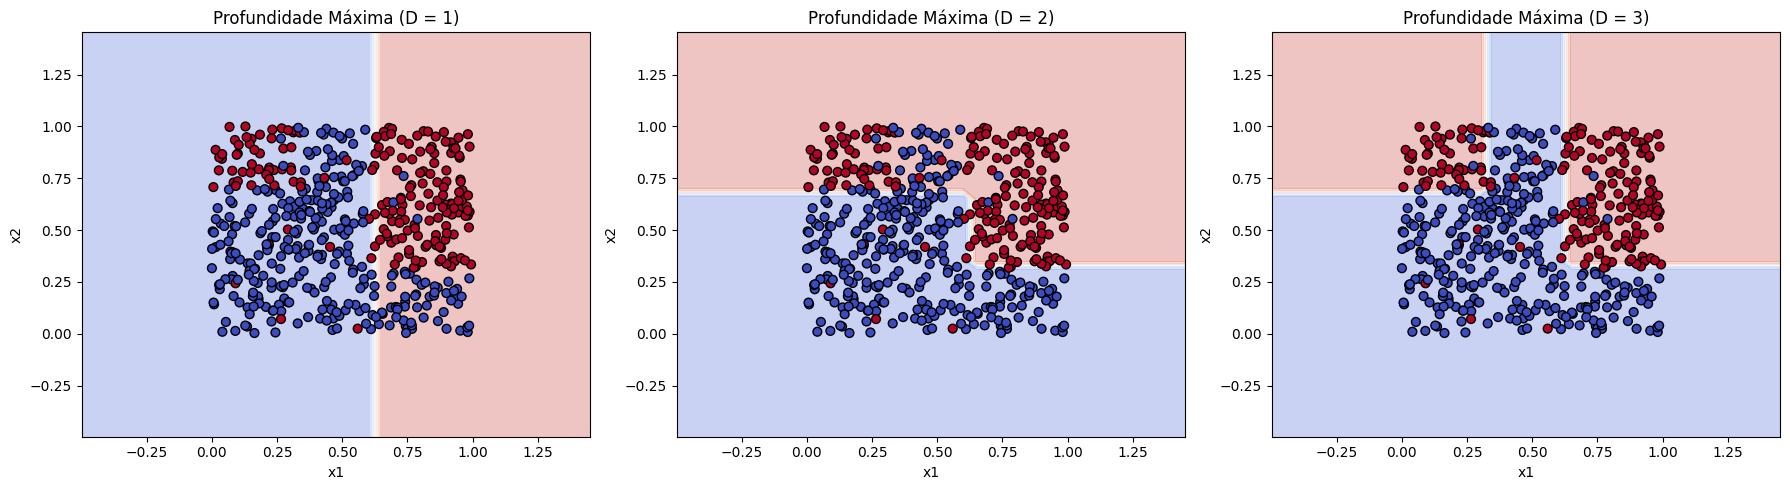

In [11]:
# Definir as profundidades exigidas pela tarefa (c)
profundidades = [1, 2, 3]

# Configurar a área de plotagem (3 gráficos lado a lado)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, depth in enumerate(profundidades):
    ax = axes[i]

    # 1. Treinar a árvore com a profundidade atual
    arvore = construir_arvore(df1, max_depth=depth, n_min=1, min_gain=0.0)

    # 2. Criar a grelha fina (grid) no plano (x1, x2)
    # Adicionamos uma margem de 0.5 para os limites do gráfico não cortarem pontos
    x1_min, x1_max = df1['x1'].min() - 0.5, df1['x1'].max() + 0.5
    x2_min, x2_max = df1['x2'].min() - 0.5, df1['x2'].max() + 0.5

    # meshgrid gera a malha com passos curtos (0.05)
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, 0.05),
                           np.arange(x2_min, x2_max, 0.05))

    # 3. Prever a classe para cada ponto da grelha
    # Achatar (ravel) as matrizes para criar um DataFrame preditivo temporário
    grid_df = pd.DataFrame({'x1': xx1.ravel(), 'x2': xx2.ravel()})

    # Calcular as previsões e remodelar (reshape) para o formato da grelha original
    Z = prever(arvore, grid_df)
    Z = Z.reshape(xx1.shape)

    # 4. Desenhar a fronteira de decisão
    # cmap='coolwarm' usa azul e vermelho para distinguir as áreas
    ax.contourf(xx1, xx2, Z, alpha=0.3, cmap='coolwarm')

    # 5. Sobrepor o gráfico de dispersão (scatter plot) dos dados reais
    scatter = ax.scatter(df1['x1'], df1['x2'], c=df1['y'], cmap='coolwarm',
                         edgecolors='k', s=40)

    ax.set_title(f'Profundidade Máxima (D = {depth})')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')

plt.tight_layout()
plt.show()

d) Treino e Teste

In [12]:
def train_test_split_estratificado(df, test_size=0.3, stratify_col='y', seed=42):
    """Realiza a separação estratificada manual do conjunto de dados."""
    np.random.seed(seed)
    indices_treino = []
    indices_teste = []

    # Iterar sobre cada classe para garantir a proporção correta
    for classe in df[stratify_col].unique():
        # Isolar os dados da classe atual
        df_classe = df[df[stratify_col] == classe]

        # Embaralhar os índices
        indices_embaralhados = np.random.permutation(df_classe.index)

        # Calcular o ponto de corte para o conjunto de teste
        tamanho_teste = int(len(df_classe) * test_size)

        # Distribuir os índices
        indices_teste.extend(indices_embaralhados[:tamanho_teste])
        indices_treino.extend(indices_embaralhados[tamanho_teste:])

    return df.loc[indices_treino], df.loc[indices_teste]

# 1. Aplicar a separação estratificada (70/30) no df1
df_treino, df_teste = train_test_split_estratificado(df1, test_size=0.3, stratify_col='y')

print(f"Tamanho do Treino: {len(df_treino)} amostras")
print(f"Tamanho do Teste: {len(df_teste)} amostras\n")

# 2. Treinar a árvore usando APENAS o conjunto de treino
# Pode ajustar a profundidade D conforme preferir (ex: D=3)
arvore_modelo = construir_arvore(df_treino, max_depth=3, n_min=5, min_gain=0.0)

# 3. Realizar as previsões no conjunto de teste
y_teste_previsto = prever(arvore_modelo, df_teste)
y_teste_real = df_teste['y'].values

# 4. Calcular e reportar a Acurácia
acuracia = np.mean(y_teste_previsto == y_teste_real)
print(f"--- Resultados da Avaliação no Teste ---")
print(f"Acurácia: {acuracia:.4f}\n")

# 5. Gerar e reportar a Matriz de Confusão
matriz_confusao = pd.crosstab(
    y_teste_real,
    y_teste_previsto,
    rownames=['Classe Real (y)'],
    colnames=['Classe Prevista']
)

print("Matriz de Confusão:")
display(matriz_confusao)

Tamanho do Treino: 351 amostras
Tamanho do Teste: 149 amostras

--- Resultados da Avaliação no Teste ---
Acurácia: 0.9664

Matriz de Confusão:


Classe Prevista,0,1
Classe Real (y),,
0,91,1
1,4,53


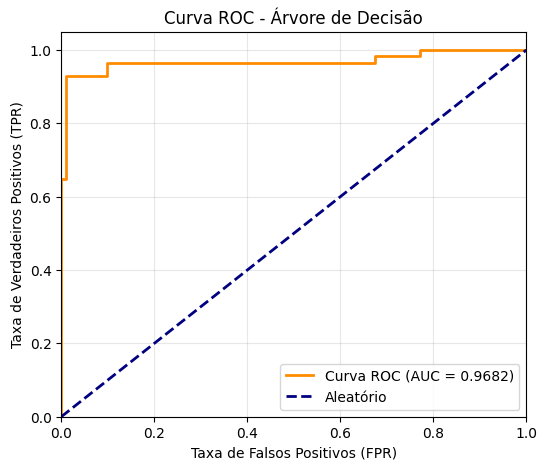

In [13]:
# Opcional: probabilidades das folhas
def prever_prob_linha(no, linha):
    """Percorre a árvore e devolve a probabilidade da classe 1."""
    if no.eh_folha():
        return no.probabilidade

    if linha[no.atributo] <= no.limiar:
        return prever_prob_linha(no.esquerdo, linha)
    else:
        return prever_prob_linha(no.direito, linha)

def prever_probabilidades(arvore, df):
    """Aplica a extração de probabilidade a todo o DataFrame."""
    return df.apply(lambda linha: prever_prob_linha(arvore, linha), axis=1).values

def calcular_roc_auc(y_true, y_prob):
    """Calcula os pontos da curva ROC e a AUC a partir do zero."""
    # Ordenar as previsões de forma decrescente
    indices_ordenados = np.argsort(y_prob)[::-1]
    y_true_ord = y_true[indices_ordenados]

    # Contagem total de positivos e negativos
    P = np.sum(y_true == 1)
    N = np.sum(y_true == 0)

    tpr_list = [0.0]
    fpr_list = [0.0]

    tp = 0
    fp = 0

    # Deslocar o limiar iterativamente sobre as probabilidades ordenadas
    for classe_real in y_true_ord:
        if classe_real == 1:
            tp += 1
        else:
            fp += 1

        tpr_list.append(tp / P)
        fpr_list.append(fp / N)

    # Calcular a Área Sob a Curva (AUC) usando a regra dos trapézios (numpy.trapezoid)
    auc = np.trapezoid(tpr_list, fpr_list)

    return fpr_list, tpr_list, auc

# --- Execução no Conjunto de Teste ---
# Obter as probabilidades para o conjunto de teste separado na alínea (d)
y_teste_prob = prever_probabilidades(arvore_modelo, df_teste)
y_teste_real = df_teste['y'].values

# Calcular métricas
fpr, tpr, auc_score = calcular_roc_auc(y_teste_real, y_teste_prob)

# Plotar a Curva ROC
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aleatório')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC - Árvore de Decisão')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

Letra e) no pdf de entrega

## Tuning de hiperparametros

a) `DecisionTreeClassifier` do scikit-learn (permitido pelo enunciado), com a correspondência:

| Hiperparâmetro do TP | Parâmetro no scikit-learn |
|---|---|
| $D$ (profundidade máxima) | `max_depth` |
| $n_{min}$ (mínimo de amostras por folha) | `min_samples_leaf` |
| `min_gain` (ganho mínimo) | `min_impurity_decrease` |

Todo o processo de **tuning** (divisão treino/teste, validação cruzada estratificada, busca em grade e busca aleatória) foi implementado sem scikit. A otimização Bayesiana usa o Optuna (TPE).

In [14]:
# O Optuna não vem instalado por padrão no Colab
!pip install -q optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 17.0 MB/s eta 0:00:00


In [15]:
import time
import itertools
import optuna
from sklearn.tree import DecisionTreeClassifier  # usado apenas como MODELO (permitido na Parte 2)

optuna.logging.set_verbosity(optuna.logging.WARNING)  # evita imprimir uma linha por trial

SEED = 42
K = 4  # número de folds da validação cruzada

b) Treino (70%) e Teste (30%)

In [16]:
atributos_tuning = [f'x{i}' for i in range(1, 6)]

df_tun_treino, df_tun_teste = train_test_split_estratificado(
    df_tuning, test_size=0.3, stratify_col='y', seed=SEED
)

X_tun_treino = df_tun_treino[atributos_tuning].values
y_tun_treino = df_tun_treino['y'].values
X_tun_teste = df_tun_teste[atributos_tuning].values
y_tun_teste = df_tun_teste['y'].values
y_true_tun_teste = df_tun_teste['y_true'].values  # usado só para análise didática

print(f"Treino (70%): {len(df_tun_treino)} amostras | Teste (30%): {len(df_tun_teste)} amostras\n")
proporcoes = pd.DataFrame({
    'Total': df_tuning['y'].value_counts(normalize=True),
    'Treino': df_tun_treino['y'].value_counts(normalize=True),
    'Teste': df_tun_teste['y'].value_counts(normalize=True),
}).round(3)
proporcoes.index.name = 'Classe (y)'
print("Proporção de classes (verificação da estratificação):")
display(proporcoes)

Treino (70%): 1051 amostras | Teste (30%): 449 amostras

Proporção de classes (verificação da estratificação):


,Total,Treino,Teste
Classe (y),,,
1,0.501,0.501,0.501
0,0.499,0.499,0.499


c) Validação cruzada estratificada K-fold

In [17]:
def kfold_estratificado(y, k=4, seed=42):
    # Gera k pares (indices_treino, indices_validacao) preservando a proporção das classes
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]

    for classe in np.unique(y):
        idx_classe = rng.permutation(np.where(y == classe)[0])
        # array_split divide a classe em k pedaços de tamanhos o mais iguais possível
        for f, pedaco in enumerate(np.array_split(idx_classe, k)):
            folds[f].extend(pedaco)

    todos = np.arange(len(y))
    divisoes = []
    for f in range(k):
        idx_val = np.sort(np.array(folds[f]))
        idx_tr = np.setdiff1d(todos, idx_val)
        divisoes.append((idx_tr, idx_val))
    return divisoes


FOLDS = kfold_estratificado(y_tun_treino, k=K, seed=SEED)

# Verificação: tamanho e proporção da classe 1 em cada fold de validação
verif = pd.DataFrame([
    {'Fold': f + 1, 'n treino': len(tr), 'n validação': len(va),
     'Prop. classe 1 (validação)': round(y_tun_treino[va].mean(), 3)}
    for f, (tr, va) in enumerate(FOLDS)
])
display(verif)

,Fold,n treino,n validação,Prop. classe 1 (validação)
0,1,788,263,0.502
1,2,788,263,0.502
2,3,788,263,0.502
3,4,789,262,0.500


In [18]:
def criar_arvore(D, n_min, min_gain):
    return DecisionTreeClassifier(
        criterion='gini',
        max_depth=int(D),
        min_samples_leaf=int(n_min),
        min_impurity_decrease=float(min_gain),
        random_state=SEED,
    )


def avaliar_config(D, n_min, min_gain, X=X_tun_treino, y=y_tun_treino, folds=FOLDS):
    # Treina uma árvore em cada fold e devolve (acurácia média, desvio-padrão entre folds)
    accs = []
    for idx_tr, idx_val in folds:
        modelo = criar_arvore(D, n_min, min_gain)
        modelo.fit(X[idx_tr], y[idx_tr])
        accs.append(np.mean(modelo.predict(X[idx_val]) == y[idx_val]))
    return np.mean(accs), np.std(accs)


def melhor_config(historico):
    # Maior acurácia média; empates desfeitos pelo menor desvio entre folds e depois pela iteração mais cedo
    ordenado = historico.sort_values(['acc_media', 'acc_desvio', 'iteracao'],
                                     ascending=[False, True, True])
    return ordenado.iloc[0]

d) Busca
| Hiperparâmetro | Grade (subconjunto discreto) | Aleatória | Bayesiana (Optuna/TPE) |
|---|---|---|---|
| $D$ | {1, 2, 3, 4, 5, 6} | uniforme em {1,…,6} | `suggest_int(1, 6)` |
| $n_{min}$ | {5, 10, 20, 30, 50} | uniforme em {5, 10, 20, 30, 50} | `suggest_categorical` |
| `min_gain` | {0, 0.001, 0.0025, 0.005, 0.01, 0.02, 0.035, 0.05} | contínuo $\mathcal{U}[0, 0.05]$ | `suggest_float(0, 0.05)` |


In [19]:
ESPACO_D = [1, 2, 3, 4, 5, 6]
ESPACO_NMIN = [5, 10, 20, 30, 50]
MIN_GAIN_INTERVALO = (0.0, 0.05)
GRADE_MIN_GAIN = [0.0, 0.001, 0.0025, 0.005, 0.01, 0.02, 0.035, 0.05]

N_ITER = 60  # orçamento (nº de configurações) da busca aleatória e da Bayesiana

In [20]:
def busca_grade(valores_D, valores_nmin, valores_gain):
    historico = []
    t0 = time.perf_counter()
    combinacoes = itertools.product(valores_D, valores_nmin, valores_gain)
    for it, (D, n_min, g) in enumerate(combinacoes, start=1):
        media, desvio = avaliar_config(D, n_min, g)
        historico.append({'iteracao': it, 'D': D, 'n_min': n_min, 'min_gain': g,
                          'acc_media': media, 'acc_desvio': desvio})
    tempo = time.perf_counter() - t0
    return pd.DataFrame(historico), tempo


hist_grade, tempo_grade = busca_grade(ESPACO_D, ESPACO_NMIN, GRADE_MIN_GAIN)
print(f"Grade: {len(hist_grade)} configurações avaliadas em {tempo_grade:.2f} s")
display(hist_grade.sort_values('acc_media', ascending=False).head(10).round(4))

Grade: 240 configurações avaliadas em 9.01 s


,iteracao,D,n_min,min_gain,acc_media,acc_desvio
233,234,6,50,0.0010,0.7832,0.1045
232,233,6,50,0.0000,0.7832,0.1045
193,194,5,50,0.0010,0.7737,0.1180
192,193,5,50,0.0000,0.7737,0.1180
216,217,6,20,0.0000,0.7737,0.1037
217,218,6,20,0.0010,0.7737,0.1037
218,219,6,20,0.0025,0.7689,0.1128
224,225,6,30,0.0000,0.7623,0.1118
225,226,6,30,0.0010,0.7623,0.1118
226,227,6,30,0.0025,0.7499,0.1324


In [21]:
def busca_aleatoria(n_iter, seed):
    rng = np.random.default_rng(seed)
    historico = []
    t0 = time.perf_counter()
    for it in range(1, n_iter + 1):
        D = int(rng.choice(ESPACO_D))
        n_min = int(rng.choice(ESPACO_NMIN))
        g = float(rng.uniform(*MIN_GAIN_INTERVALO))  # min_gain contínuo uniforme
        media, desvio = avaliar_config(D, n_min, g)
        historico.append({'iteracao': it, 'D': D, 'n_min': n_min, 'min_gain': g,
                          'acc_media': media, 'acc_desvio': desvio})
    tempo = time.perf_counter() - t0
    return pd.DataFrame(historico), tempo


hist_aleatoria, tempo_aleatoria = busca_aleatoria(N_ITER, seed=SEED)
print(f"Aleatória: {len(hist_aleatoria)} configurações avaliadas em {tempo_aleatoria:.2f} s")
display(hist_aleatoria.sort_values('acc_media', ascending=False).head(10).round(4))

Aleatória: 60 configurações avaliadas em 1.79 s


,iteracao,D,n_min,min_gain,acc_media,acc_desvio
25,26,5,5,0.0004,0.6509,0.0855
48,49,4,10,0.0044,0.6251,0.0150
2,3,2,5,0.0488,0.6194,0.0129
0,1,1,30,0.0219,0.6194,0.0129
4,5,4,5,0.0225,0.6194,0.0129
5,6,4,10,0.0463,0.6194,0.0129
6,7,5,30,0.0411,0.6194,0.0129
7,8,4,20,0.0114,0.6194,0.0129
8,9,1,20,0.0032,0.6194,0.0129
9,10,6,50,0.0316,0.6194,0.0129


In [22]:
def busca_bayesiana(n_iter, seed):
    historico = []

    def objetivo(trial):
        D = trial.suggest_int('D', 1, 6)
        n_min = trial.suggest_categorical('n_min', ESPACO_NMIN)
        g = trial.suggest_float('min_gain', *MIN_GAIN_INTERVALO)
        media, desvio = avaliar_config(D, n_min, g)
        historico.append({'iteracao': len(historico) + 1, 'D': D, 'n_min': n_min, 'min_gain': g,
                          'acc_media': media, 'acc_desvio': desvio})
        return media  # o Optuna maximiza a acurácia média de validação

    estudo = optuna.create_study(direction='maximize',
                                 sampler=optuna.samplers.TPESampler(seed=seed))
    t0 = time.perf_counter()
    estudo.optimize(objetivo, n_trials=n_iter)
    tempo = time.perf_counter() - t0  # inclui o overhead do próprio TPE
    return pd.DataFrame(historico), tempo, estudo


hist_bayes, tempo_bayes, estudo_bayes = busca_bayesiana(N_ITER, seed=SEED)
print(f"Bayesiana: {len(hist_bayes)} trials avaliados em {tempo_bayes:.2f} s")
display(hist_bayes.sort_values('acc_media', ascending=False).head(10).round(4))

Bayesiana: 60 trials avaliados em 2.81 s


,iteracao,D,n_min,min_gain,acc_media,acc_desvio
51,52,6,20,0.0020,0.7784,0.0969
25,26,6,20,0.0013,0.7737,0.1037
50,51,6,20,0.0011,0.7737,0.1037
53,54,6,20,0.0011,0.7737,0.1037
49,50,6,20,0.0008,0.7737,0.1037
47,48,6,20,0.0005,0.7737,0.1037
56,57,6,20,0.0002,0.7737,0.1037
52,53,6,20,0.0027,0.7689,0.1128
31,32,6,30,0.0019,0.7642,0.1177
43,44,6,30,0.0016,0.7642,0.1177


In [23]:
historicos = {'Grade': hist_grade, 'Aleatória': hist_aleatoria, 'Bayesiana': hist_bayes}
tempos = {'Grade': tempo_grade, 'Aleatória': tempo_aleatoria, 'Bayesiana': tempo_bayes}

melhores = {}
linhas = []
for nome, hist in historicos.items():
    m = melhor_config(hist)
    melhores[nome] = m
    linhas.append({
        'Estratégia': nome,
        'D*': int(m['D']),
        'n_min*': int(m['n_min']),
        'min_gain*': round(m['min_gain'], 5),
        'Acc. média CV': round(m['acc_media'], 4),
        'Desvio entre folds': round(m['acc_desvio'], 4),
        'Iteração do ótimo': int(m['iteracao']),
        'Configurações': len(hist),
        'Treinamentos (config × K)': len(hist) * K,
        'Tempo (s)': round(tempos[nome], 2),
    })

tabela_resumo = pd.DataFrame(linhas).set_index('Estratégia')
display(tabela_resumo)

,D*,n_min*,min_gain*,Acc. média CV,Desvio entre folds,Iteração do ótimo,Configurações,Treinamentos (config × K),Tempo (s)
Estratégia,,,,,,,,,
Grade,6,50,0.00000,0.7832,0.1045,233,240,960,9.01
Aleatória,5,5,0.00037,0.6509,0.0855,26,60,240,1.79
Bayesiana,6,20,0.00199,0.7784,0.0969,52,60,240,2.81


e) Traço de otimização

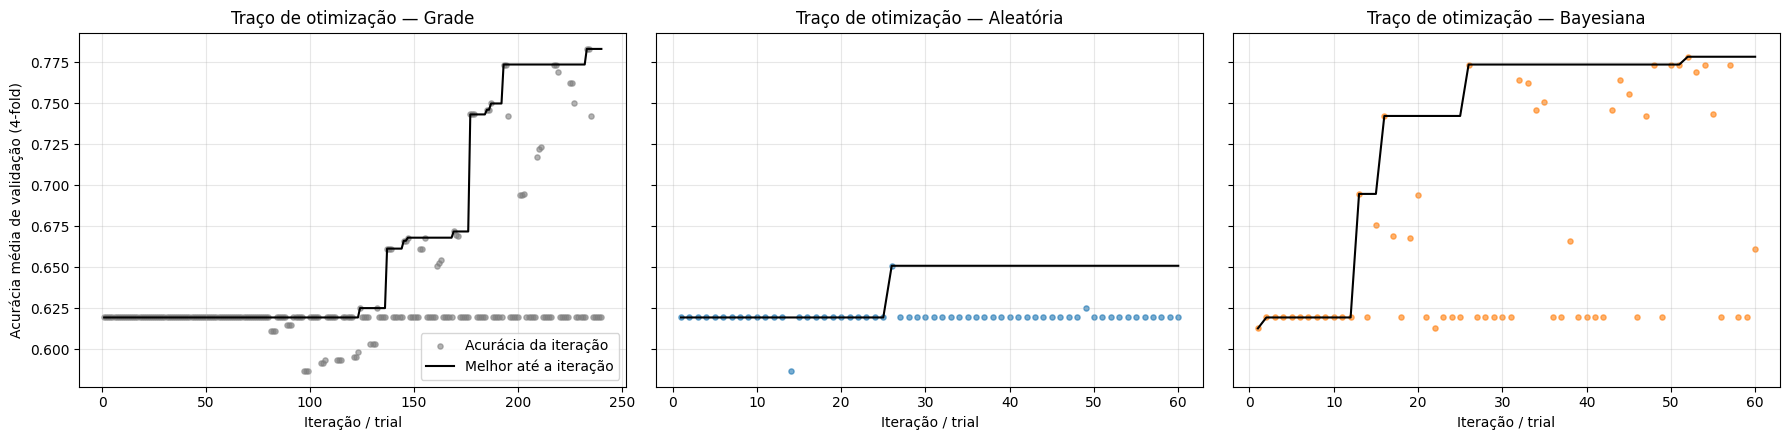

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
cores = {'Grade': 'tab:gray', 'Aleatória': 'tab:blue', 'Bayesiana': 'tab:orange'}

for ax, (nome, hist) in zip(axes, historicos.items()):
    ax.scatter(hist['iteracao'], hist['acc_media'], s=14, alpha=0.6,
               color=cores[nome], label='Acurácia da iteração')
    ax.plot(hist['iteracao'], hist['acc_media'].cummax(), color='black', lw=1.5,
            label='Melhor até a iteração')
    ax.set_title(f'Traço de otimização — {nome}')
    ax.set_xlabel('Iteração / trial')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Acurácia média de validação (4-fold)')
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

f) Curvas de convergência

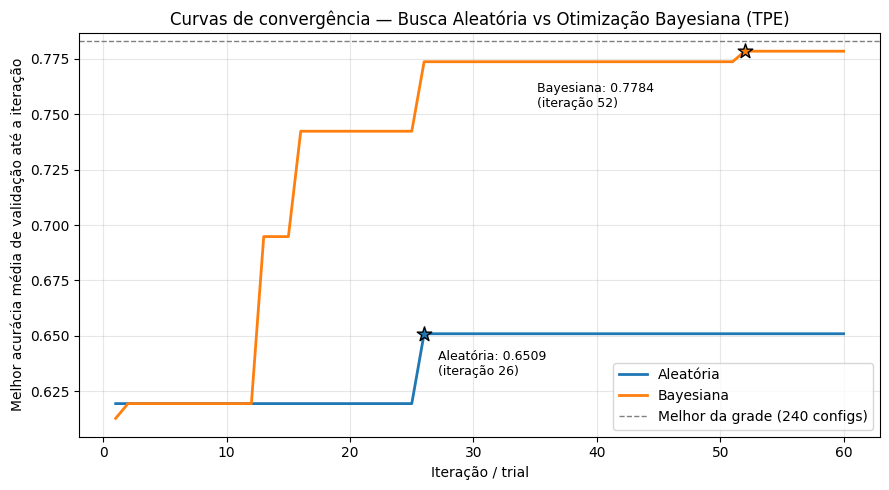

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

for nome in ['Aleatória', 'Bayesiana']:
    hist = historicos[nome]
    melhor_acum = hist['acc_media'].cummax().values
    it = hist['iteracao'].values
    ax.plot(it, melhor_acum, lw=2, color=cores[nome], label=nome)
    # Marcador no ponto ótimo: primeira iteração em que o melhor valor final foi atingido
    i_otimo = int(np.argmax(melhor_acum >= melhor_acum[-1]))
    ax.scatter(it[i_otimo], melhor_acum[i_otimo], s=120, marker='*', color=cores[nome],
               edgecolors='k', zorder=5)
    ax.annotate(f'{nome}: {melhor_acum[i_otimo]:.4f}\n(iteração {it[i_otimo]})',
                (it[i_otimo], melhor_acum[i_otimo]), textcoords='offset points',
                xytext=(10, -30) if nome == 'Aleatória' else (-150, -40), fontsize=9)

ax.axhline(melhores['Grade']['acc_media'], color='gray', ls='--', lw=1,
           label=f"Melhor da grade ({len(hist_grade)} configs)")
ax.set_xlabel('Iteração / trial')
ax.set_ylabel('Melhor acurácia média de validação até a iteração')
ax.set_title('Curvas de convergência — Busca Aleatória vs Otimização Bayesiana (TPE)')
ax.grid(alpha=0.3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

g) Heatmaps da busca em grade


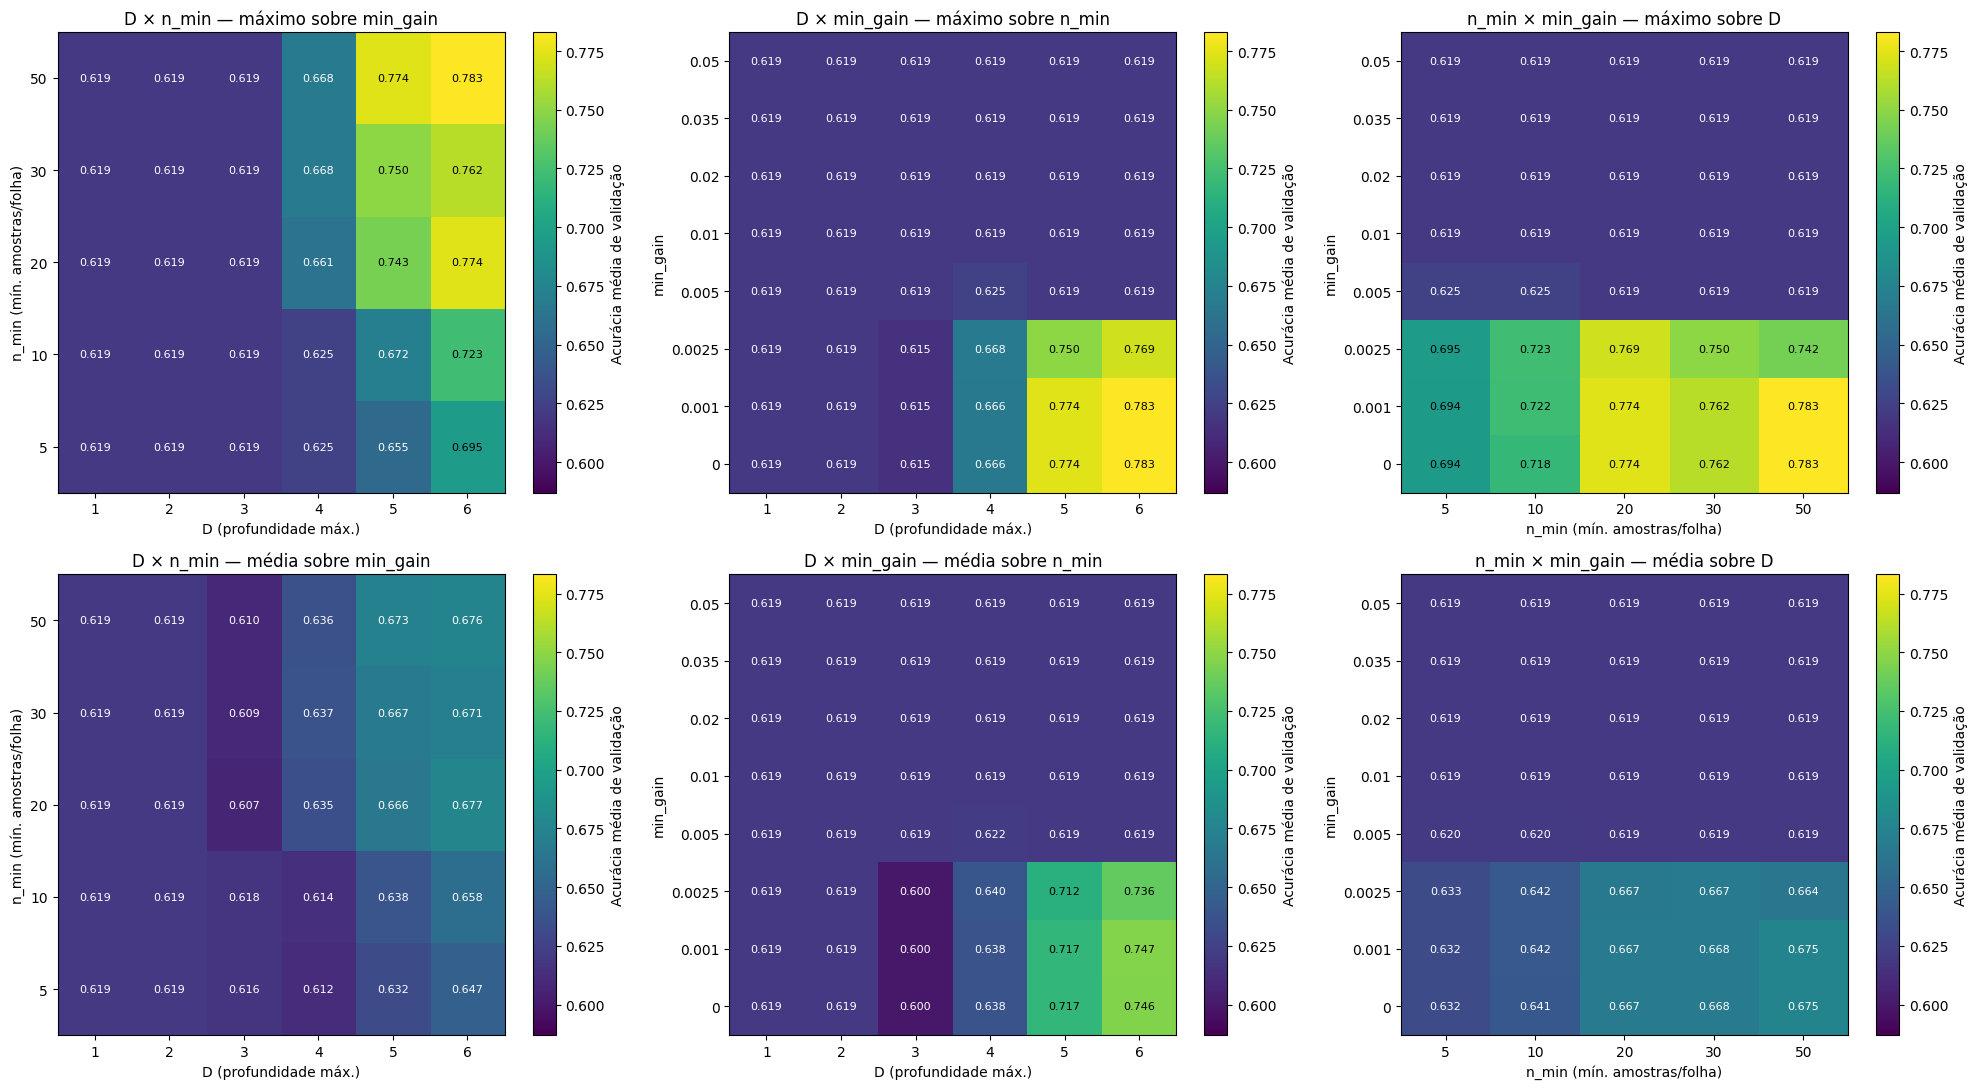

In [26]:
pares = [('D', 'n_min'), ('D', 'min_gain'), ('n_min', 'min_gain')]
rotulos = {'D': 'D (profundidade máx.)', 'n_min': 'n_min (mín. amostras/folha)', 'min_gain': 'min_gain'}

vmin, vmax = hist_grade['acc_media'].min(), hist_grade['acc_media'].max()
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

for linha, agg in enumerate(['max', 'mean']):
    for col, (ti, tj) in enumerate(pares):
        ax = axes[linha, col]
        tabela = hist_grade.pivot_table(index=tj, columns=ti, values='acc_media', aggfunc=agg)
        im = ax.imshow(tabela.values, origin='lower', aspect='auto', cmap='viridis',
                       vmin=vmin, vmax=vmax)
        ax.set_xticks(range(tabela.shape[1]))
        ax.set_xticklabels([f'{v:g}' for v in tabela.columns])
        ax.set_yticks(range(tabela.shape[0]))
        ax.set_yticklabels([f'{v:g}' for v in tabela.index])
        ax.set_xlabel(rotulos[ti])
        ax.set_ylabel(rotulos[tj])
        terceiro = ({'D', 'n_min', 'min_gain'} - {ti, tj}).pop()
        ax.set_title(f'{ti} × {tj} — {"máximo" if agg == "max" else "média"} sobre {terceiro}')
        # Valores escritos em cada célula
        for a in range(tabela.shape[0]):
            for b in range(tabela.shape[1]):
                v = tabela.values[a, b]
                ax.text(b, a, f'{v:.3f}', ha='center', va='center', fontsize=8,
                        color='white' if v < (vmin + vmax) / 2 else 'black')
        fig.colorbar(im, ax=ax, label='Acurácia média de validação')

plt.tight_layout()
plt.show()

h) Importância, estabilidade e interações dos hiperparâmetros


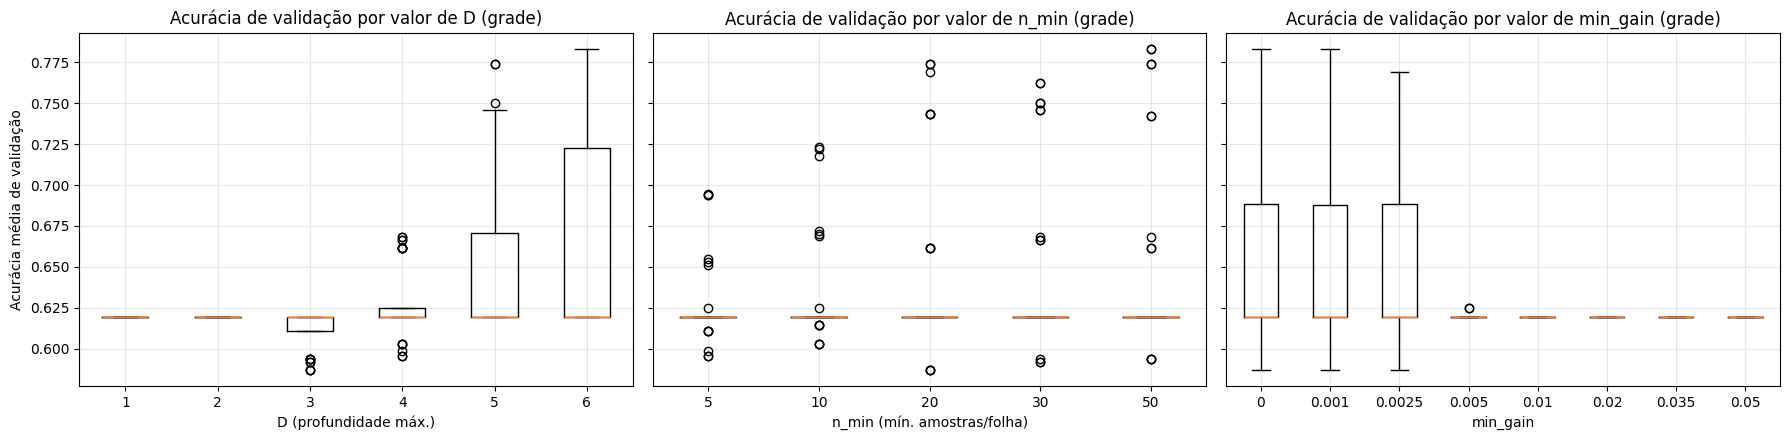

Importância simples (amplitude das médias marginais na grade):


,Melhor valor (média marginal),Acc. marginal máx.,Acc. marginal mín.,Amplitude
Hiperparâmetro,,,,
D,6.000,0.6658,0.6120,0.0537
min_gain,0.001,0.6567,0.6194,0.0373
n_min,50.000,0.6390,0.6243,0.0146


Importância segundo o Optuna (fANOVA, trials da Bayesiana):


,Importância
min_gain,0.761
D,0.203
n_min,0.036


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, hp in zip(axes, ['D', 'n_min', 'min_gain']):
    valores = sorted(hist_grade[hp].unique())
    dados = [hist_grade.loc[hist_grade[hp] == v, 'acc_media'] for v in valores]
    ax.boxplot(dados, tick_labels=[f'{v:g}' for v in valores])
    ax.set_xlabel(rotulos[hp])
    ax.set_title(f'Acurácia de validação por valor de {hp} (grade)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Acurácia média de validação')
plt.tight_layout()
plt.show()

# Importância simples: amplitude das médias marginais na grade
importancia = []
for hp in ['D', 'n_min', 'min_gain']:
    marg = hist_grade.groupby(hp)['acc_media'].mean()
    importancia.append({'Hiperparâmetro': hp,
                        'Melhor valor (média marginal)': marg.idxmax(),
                        'Acc. marginal máx.': round(marg.max(), 4),
                        'Acc. marginal mín.': round(marg.min(), 4),
                        'Amplitude': round(marg.max() - marg.min(), 4)})
tabela_importancia = pd.DataFrame(importancia).set_index('Hiperparâmetro').sort_values('Amplitude', ascending=False)
print("Importância simples (amplitude das médias marginais na grade):")
display(tabela_importancia)

# Importância segundo o Optuna (fANOVA sobre os trials da busca Bayesiana)
try:
    imp_optuna = optuna.importance.get_param_importances(estudo_bayes)
    print("Importância segundo o Optuna (fANOVA, trials da Bayesiana):")
    display(pd.Series(imp_optuna, name='Importância').round(3).to_frame())
except Exception as e:
    print(f"Importância do Optuna indisponível: {e}")

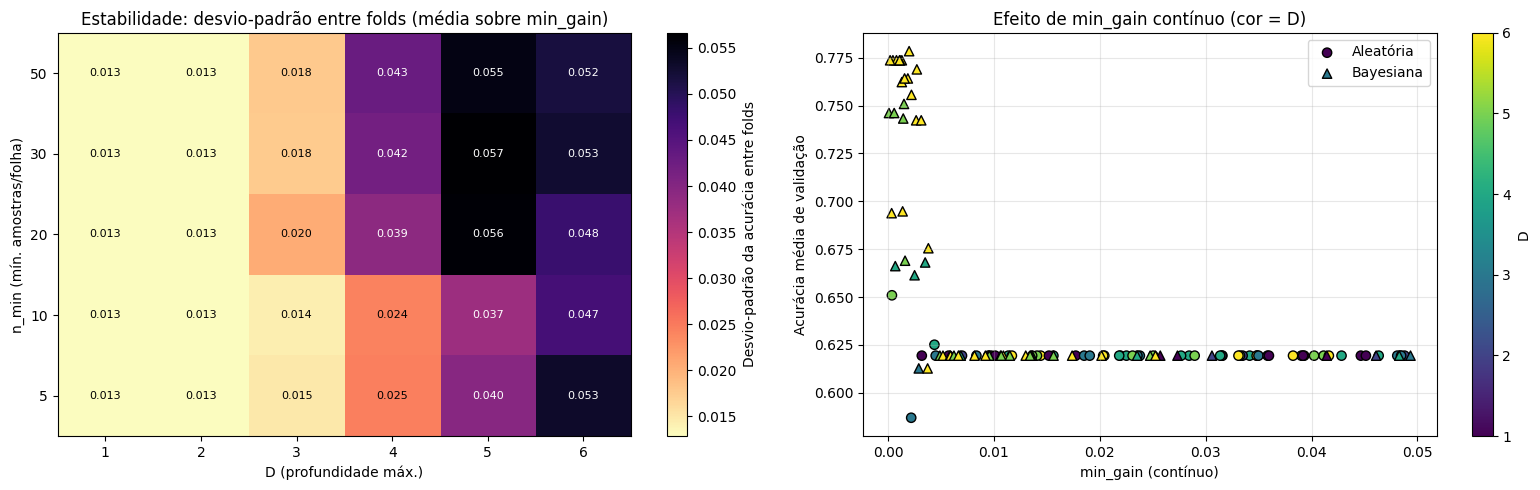

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) Estabilidade: desvio-padrão da acurácia entre os 4 folds (média sobre min_gain)
ax = axes[0]
tab_std = hist_grade.pivot_table(index='n_min', columns='D', values='acc_desvio', aggfunc='mean')
im = ax.imshow(tab_std.values, origin='lower', aspect='auto', cmap='magma_r')
ax.set_xticks(range(tab_std.shape[1])); ax.set_xticklabels(tab_std.columns)
ax.set_yticks(range(tab_std.shape[0])); ax.set_yticklabels(tab_std.index)
for a in range(tab_std.shape[0]):
    for b in range(tab_std.shape[1]):
        v = tab_std.values[a, b]
        meio = (np.nanmin(tab_std.values) + np.nanmax(tab_std.values)) / 2
        ax.text(b, a, f'{v:.3f}', ha='center', va='center', fontsize=8,
                color='white' if v > meio else 'black')
ax.set_xlabel(rotulos['D']); ax.set_ylabel(rotulos['n_min'])
ax.set_title('Estabilidade: desvio-padrão entre folds (média sobre min_gain)')
fig.colorbar(im, ax=ax, label='Desvio-padrão da acurácia entre folds')

# (b) min_gain contínuo: todas as configurações das buscas aleatória e Bayesiana
ax = axes[1]
hist_cont = pd.concat([hist_aleatoria.assign(estrategia='Aleatória'),
                       hist_bayes.assign(estrategia='Bayesiana')])
marcadores = {'Aleatória': 'o', 'Bayesiana': '^'}
for nome, sub in hist_cont.groupby('estrategia'):
    sc = ax.scatter(sub['min_gain'], sub['acc_media'], c=sub['D'], cmap='viridis',
                    vmin=1, vmax=6, marker=marcadores[nome], edgecolors='k', s=45, label=nome)
fig.colorbar(sc, ax=ax, label='D')
ax.set_xlabel('min_gain (contínuo)')
ax.set_ylabel('Acurácia média de validação')
ax.set_title('Efeito de min_gain contínuo (cor = D)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

i) Análise crítica: importância e interpretabilidade dos hiperparâmetros:
Escrita no pdf entregue junto a esse código

j) Avaliação final no teste (30%)


Concordância entre y e y_true no teste (≈ acurácia de um classificador perfeito medida com y): 0.9866



,"Tripla (D*, n_min*, min_gain*)",Acc. CV (70%),Acc. teste (y),Acc. teste (y_true),Profundidade real,Nº de folhas
Estratégia,,,,,,
Grade,"(6, 50, 0.0000)",0.7832,0.7216,0.7305,6,15
Aleatória,"(5, 5, 0.0004)",0.6509,0.6236,0.6325,5,20
Bayesiana,"(6, 20, 0.0020)",0.7784,0.7661,0.7795,6,16


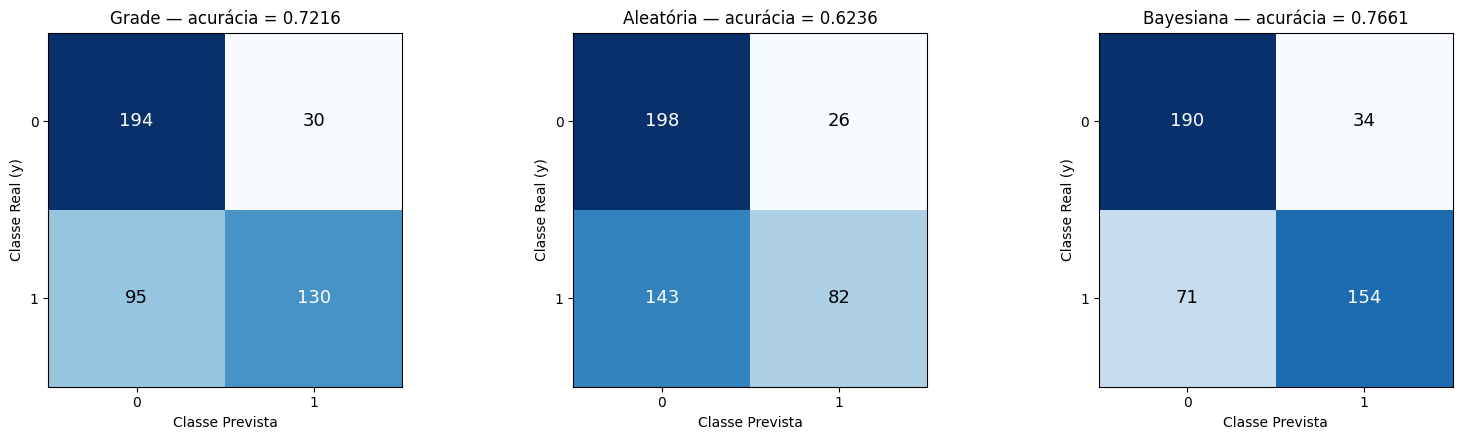

In [29]:
teto_ruido = np.mean(y_tun_teste == y_true_tun_teste)
print(f"Concordância entre y e y_true no teste (≈ acurácia de um classificador perfeito medida com y): {teto_ruido:.4f}\n")

resultados_teste = []
matrizes = {}
for nome, m in melhores.items():
    modelo_final = criar_arvore(m['D'], m['n_min'], m['min_gain'])
    modelo_final.fit(X_tun_treino, y_tun_treino)
    pred = modelo_final.predict(X_tun_teste)

    matrizes[nome] = pd.crosstab(pd.Series(y_tun_teste, name='Classe Real (y)'),
                                 pd.Series(pred, name='Classe Prevista'))
    resultados_teste.append({
        'Estratégia': nome,
        'Tripla (D*, n_min*, min_gain*)': f"({int(m['D'])}, {int(m['n_min'])}, {m['min_gain']:.4f})",
        'Acc. CV (70%)': round(m['acc_media'], 4),
        'Acc. teste (y)': round(np.mean(pred == y_tun_teste), 4),
        'Acc. teste (y_true)': round(np.mean(pred == y_true_tun_teste), 4),
        'Profundidade real': modelo_final.get_depth(),
        'Nº de folhas': modelo_final.get_n_leaves(),
    })

tabela_teste = pd.DataFrame(resultados_teste).set_index('Estratégia')
display(tabela_teste)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nome, mat) in zip(axes, matrizes.items()):
    ax.imshow(mat.values, cmap='Blues')
    ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
    ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
    for a in range(mat.shape[0]):
        for b in range(mat.shape[1]):
            ax.text(b, a, mat.values[a, b], ha='center', va='center', fontsize=13,
                    color='white' if mat.values[a, b] > mat.values.max() / 2 else 'black')
    ax.set_xlabel('Classe Prevista'); ax.set_ylabel('Classe Real (y)')
    ax.set_title(f"{nome} — acurácia = {tabela_teste.loc[nome, 'Acc. teste (y)']:.4f}")
plt.tight_layout()
plt.show()

In [32]:
# Resumo compacto dos resultados (útil para copiar para o relatório)
print("=== MELHORES CONFIGURAÇÕES (CV no treino) ===")
print(tabela_resumo.to_string())
print("\n=== TESTE (30%) ===")
print(tabela_teste.to_string())
print("\n=== IMPORTÂNCIA (amplitude marginal) ===")
print(tabela_importancia.to_string())

=== MELHORES CONFIGURAÇÕES (CV no treino) ===
            D*  n_min*  min_gain*  Acc. média CV  Desvio entre folds  Iteração do ótimo  Configurações  Treinamentos (config × K)  Tempo (s)
Estratégia                                                                                                                                  
Grade        6      50    0.00000         0.7832              0.1045                233            240                        960       9.01
Aleatória    5       5    0.00037         0.6509              0.0855                 26             60                        240       1.79
Bayesiana    6      20    0.00199         0.7784              0.0969                 52             60                        240       2.81

=== TESTE (30%) ===
           Tripla (D*, n_min*, min_gain*)  Acc. CV (70%)  Acc. teste (y)  Acc. teste (y_true)  Profundidade real  Nº de folhas
Estratégia                                                                                           

Parágrafo técnico de discussão (eficiência amostral, custo, estabilidade e bordas): escrito à mão, no PDF de entrega.

## Finalizando

In [33]:
print("That's all folks!")

That's all folks!
